In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import mannwhitneyu
from scipy.stats import spearmanr, pearsonr
from matplotlib.ticker import AutoMinorLocator
from tqdm import trange
import matplotlib.ticker as ticker
import seaborn as sns
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

DATA_PATH2 = "../../18-finalize/processed-data/"
OUT_PATH   = "figures/"
MS_COLOR   = "#DDAA33"
Y2H_COLOR  = "#BB5566"
MS_COLOR_LIGHT = "#EECC66" #color for static (in complex)
MS_COLOR_DARK  = "#997700" #color for dynamic (not in complex)

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titlepad": 25,
    "font.family": "sans-serif",
    "font.sans-serif": "Arial",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

In [2]:
# load the datasets with node centrality information and get nodes in both
nodes = pd.read_pickle(f"{DATA_PATH2}20260210-s288c-ANnnotated-Yeast-Interactome.pkl")

# --- Flip sign of cagiada-dG so downstream code uses the corrected values ---
nodes["cagiada-dG"] = -nodes["cagiada-dG"]

# determine which nodes are hubs based on percentile cutoff for betweenness centrality
cut = 0.10
ms_threshold = nodes['betweenness_centrality'].quantile(1 - cut)



In [3]:
# Filter nodes to remove proteins with low pLDDT and/or are membrane proteins (TM) with/without signal peptide (SP)
filtered_nodes = nodes[
    (nodes['mean_plddt'] >= 70) &
    (~nodes['DeepTMHMM_class'].isin(['BETA', 'TM', 'SP+TM']))
].copy()

ms_hubs     = filtered_nodes[filtered_nodes['betweenness_centrality'] >= ms_threshold]
ms_nothub   = filtered_nodes[filtered_nodes['betweenness_centrality'] <  ms_threshold]

# Print stats to for nodes
print(f"Original rows: {len(nodes)}")
print(f"Filtered rows: {len(filtered_nodes)}")

print(f"Threshold for defining a hub in MS data is {ms_threshold:.5f}; there are {len(ms_hubs)} hubs and {len(ms_nothub)} non hubs")

Original rows: 3927
Filtered rows: 2528
Threshold for defining a hub in MS data is 0.00178; there are 297 hubs and 2231 non hubs


## Supplement Fig 4A

* Create Box plots comparing protein turnover half-lives (t1/2, min) between static and dynamic bottleneck proteins (high betweenness centrality) in the AE-MS network

In [4]:
def bootstrap_ci_median(values, B=1_000_000, ci=95, random_state=42):
    """
    Nonparametric bootstrap CI for the median
    values: 1D array-like
    B: number of bootstrap resamples
    ci: confidence level (e.g., 95)
    """
    vals = np.asarray(values)
    vals = vals[np.isfinite(vals)]
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, np.nan
    
    rng = np.random.default_rng(random_state)
    medians = np.empty(B, dtype=np.float32)
    
    for b in trange(B, desc="Bootstrapping medians", leave=False):
        sample = rng.choice(vals, size=n, replace=True)
        medians[b] = np.median(sample)
    
    median_hat = np.median(vals)
    alpha = 100 - ci
    lower = np.percentile(medians, alpha / 2)
    upper = np.percentile(medians, 100 - alpha / 2)
    return median_hat, lower, upper

# Ensure boolean
ms_hubs['in_complex'] = ms_hubs['in_complex'].astype(bool)

# Split into Static (in complex) vs Dynamic (not in complex)
static_vals = ms_hubs[ms_hubs['in_complex']]['Villen_halflife_min']\
    .replace([np.inf, -np.inf], np.nan).dropna()
dynamic_vals = ms_hubs[~ms_hubs['in_complex']]['Villen_halflife_min']\
    .replace([np.inf, -np.inf], np.nan).dropna()

# NEW VARIABLE 
groups_step3 = [
    ("Static", static_vals, MS_COLOR_LIGHT),
    ("Dynamic", dynamic_vals, MS_COLOR_DARK),
]

print("=== Protein counts in Betweenness Hubs (MS) ===")
for label, vals, _ in groups_step3:
    print(f"{label:8}: n = {len(vals)}")

# Bootstrapped medians
print("\n=== Bootstrapped median half-life (95% CI) ===")
medians, ci_lowers, ci_uppers = [], [], []
for label, vals, color in groups_step3:
    m, lo, hi = bootstrap_ci_median(vals, B=1_000_000, random_state=42)
    medians.append(m)
    ci_lowers.append(lo)
    ci_uppers.append(hi)
    print(f"{label:8}: median = {m:.1f} min, 95% CI = ({lo:.1f}, {hi:.1f})")

/tmp/ipykernel_1648773/3976755123.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ms_hubs['in_complex'] = ms_hubs['in_complex'].astype(bool)


=== Protein counts in Betweenness Hubs (MS) ===
Static  : n = 139
Dynamic : n = 115

=== Bootstrapped median half-life (95% CI) ===


Static  : median = 132.0 min, 95% CI = (121.8, 140.4)


Dynamic : median = 120.6 min, 95% CI = (101.4, 141.0)


In [5]:
# Mann-Whitney U test
u_stat, p_val = mannwhitneyu(static_vals, dynamic_vals, alternative='greater')
print("\n=== Mann–Whitney U test (Static vs Dynamic hubs) ===")
print(f"n(Static) = {len(static_vals)}, n(Dynamic) = {len(dynamic_vals)}")
print(f"median(Static) = {np.median(static_vals):.1f}, median(Dynamic) = {np.median(dynamic_vals):.1f}")
print(f"U = {u_stat:.1f}, p = {p_val:.2g}")
stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "N.S."
print(f"Significance: {stars}")


=== Mann–Whitney U test (Static vs Dynamic hubs) ===
n(Static) = 139, n(Dynamic) = 115
median(Static) = 132.0, median(Dynamic) = 120.6
U = 8294.5, p = 0.3
Significance: N.S.


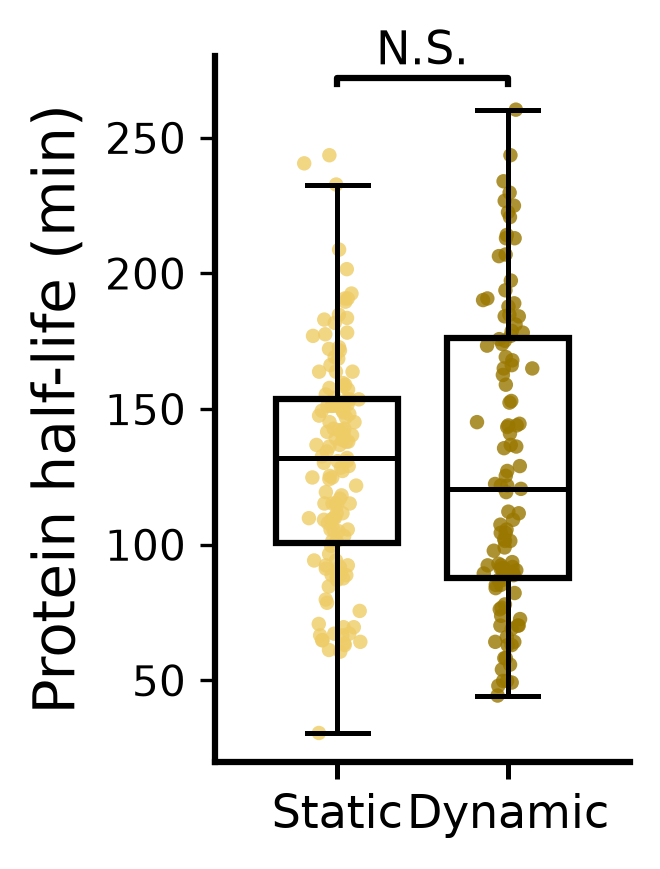

In [6]:
def add_bracket_with_text(ax, x1, x2, y, text):
    y_top = y + 2    
    ax.plot([x1, x1, x2, x2],
            [y,  y_top, y_top, y],
            lw=1.5, 
            c="black",
            clip_on=False) 
    ax.text((x1 + x2)/2, 
            y_top + 1.05, 
            text,
            ha="center", 
            va="bottom", 
            fontsize=11,
           zorder=4)

# Prepare plot
fig, ax = plt.subplots(figsize=(2.3, 3))

positions = [1.0, 1.7]
group_data = [static_vals, dynamic_vals]
group_colors = [MS_COLOR_LIGHT, MS_COLOR_DARK]

# Scatter (jittered)
for pos, (vals, color) in zip(positions, zip(group_data, group_colors)):
    x_jitter = pos + np.random.normal(0, 0.04, size=len(vals))
    ax.scatter(x_jitter, vals, s=12, color=color,
               alpha=0.8, edgecolor="none", zorder=2)

# --- Boxplots on top: outlines only, no fill, no fliers ---
# Boxplots on top
bp = ax.boxplot(
    group_data,
    positions=[1, 1.7],
    widths=0.5,
    patch_artist=True,
    showfliers=False,
)

ax.set_xticks([1, 1.7])
ax.set_xticklabels(["Top\n10%", "Bottom\n90%"])

for box in bp["boxes"]:
    box.set_facecolor("none")
    box.set_edgecolor("black")
    box.set_linewidth(1.5)
    box.set_zorder(3)

for element in ["whiskers", "caps", "medians"]:
    for line in bp[element]:
        line.set_color("black")
        line.set_linewidth(1.2)
        line.set_zorder(3)

# === 3. X-axis labels ===
ax.set_xticks(positions)
ax.set_xticklabels(["Static", "Dynamic"],
                       fontsize=11)
ax.tick_params(axis="x", length=4, width=1.2)

labs = ax.get_xticklabels()
labs[0].set_color("black")
labs[1].set_color("black")

# Styling
ax.set_ylim(20, 280)
ax.set_ylabel('Protein half-life (min)', fontsize=14)
bracket_y = 260
bracket_h = 2

# Spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)


# Significance bracket
add_bracket_with_text(ax, positions[0], positions[1], y=270, text=stars)

# Bottom group label: "AE-MS" style
trans = ax.get_xaxis_transform()
#ax.plot([1.0, 1.7], [-0.26, -0.26], transform=trans, clip_on=False, color=MS_COLOR, lw=2.5)
#ax.text(1.4, -0.28, "AE-MS", transform=trans, ha="center", va="top",
#        fontsize=11, fontweight="bold", color=MS_COLOR)

plt.tight_layout()
plt.savefig("Supp4-A.svg", dpi=400, bbox_inches='tight')
plt.show()

## Supplement Fig 4B-E

* Create Box plots comparing stability metrices and melting point between static and dynamic bottleneck proteins (high betweenness centrality) in the AE-MS network

In [7]:
# === Define the 4 stability metrics ===
stability_list = [
    ("Ghosh-Dill-dG",            "Ghosh-Dill ΔG"),
    ("cagiada-dG",               "Cagiada ΔG"),
    ("Rosetta_best_total_score", "Rosetta Total Score"),
    ("meltome-melting-point",    "Melting Point Tm (°C)"),
]

# === Extract clean values: Static vs Dynamic hubs ===
groups_step4 = []
for col, name in stability_list:
    if col == 'meltome-melting-point':
        data = ms_hubs[ms_hubs['meltome-fit-R2'] >= 0.9]   # High-quality meltome only
    else:
        data = ms_hubs
    
    static_vals  = data[data['in_complex']][col].replace([np.inf, -np.inf], np.nan).dropna()
    dynamic_vals = data[~data['in_complex']][col].replace([np.inf, -np.inf], np.nan).dropna()
    
    groups_step4.append((name, static_vals, dynamic_vals))

print("=== BOOTSTRAPPED MEDIANS (95% CI) – Static vs Dynamic in Betweenness Hubs ===\n")
for name, static_vals, dynamic_vals in groups_step4:
    if len(static_vals) < 5 or len(dynamic_vals) < 5:
        print(f"{name:30}: insufficient data")
        continue
    m_s, lo_s, hi_s = bootstrap_ci_median(static_vals, random_state=42)
    m_d, lo_d, hi_d = bootstrap_ci_median(dynamic_vals, random_state=42)
    print(f"{name:30} | Static:  {m_s:6.2f} [{lo_s:.1f}, {hi_s:.1f}]  (n={len(static_vals)})")
    print(f"{'':30} | Dynamic: {m_d:6.2f} [{lo_d:.1f}, {hi_d:.1f}]  (n={len(dynamic_vals)})\n")

=== BOOTSTRAPPED MEDIANS (95% CI) – Static vs Dynamic in Betweenness Hubs ===



Ghosh-Dill ΔG                  | Static:  -11.14 [-12.3, -10.4]  (n=161)
                               | Dynamic: -10.62 [-11.9, -10.1]  (n=136)



Cagiada ΔG                     | Static:  -21.06 [-22.6, -18.3]  (n=161)
                               | Dynamic: -20.63 [-23.1, -17.9]  (n=136)



Rosetta Total Score            | Static:  -1206.32 [-1292.0, -1030.0]  (n=161)
                               | Dynamic: -1165.50 [-1302.7, -982.5]  (n=136)



Melting Point Tm (°C)          | Static:   48.32 [47.5, 49.0]  (n=113)
                               | Dynamic:  48.94 [47.7, 50.2]  (n=102)



In [8]:
print("\n=== MANN–WHITNEY U TESTS (Static vs Dynamic in Betweenness Hubs) ===\n")

results = []
for name, static_vals, dynamic_vals in groups_step4:
    if len(static_vals) < 5 or len(dynamic_vals) < 5:
        print(f"{name:30}: insufficient data for test")
        results.append((name, np.nan, 1.0))
        continue
    
    u_stat, p_val = mannwhitneyu(static_vals, dynamic_vals, alternative='greater')
    stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "N.S."
    
    print(f"{name:30} | U = {u_stat:6.0f}, p = {p_val:.2g} {stars}")
    print(f"{'':32} Static median = {np.median(static_vals):.2f}, Dynamic = {np.median(dynamic_vals):.2f}\n")
    
    results.append((name, u_stat, p_val))


=== MANN–WHITNEY U TESTS (Static vs Dynamic in Betweenness Hubs) ===

Ghosh-Dill ΔG                  | U =  10366, p = 0.79 N.S.
                                 Static median = -11.14, Dynamic = -10.62

Cagiada ΔG                     | U =  11285, p = 0.32 N.S.
                                 Static median = -21.06, Dynamic = -20.63

Rosetta Total Score            | U =  10859, p = 0.55 N.S.
                                 Static median = -1206.32, Dynamic = -1165.50

Melting Point Tm (°C)          | U =   5069, p = 0.94 N.S.
                                 Static median = 48.32, Dynamic = 48.94



Saved: Supp4B-E.1.svg


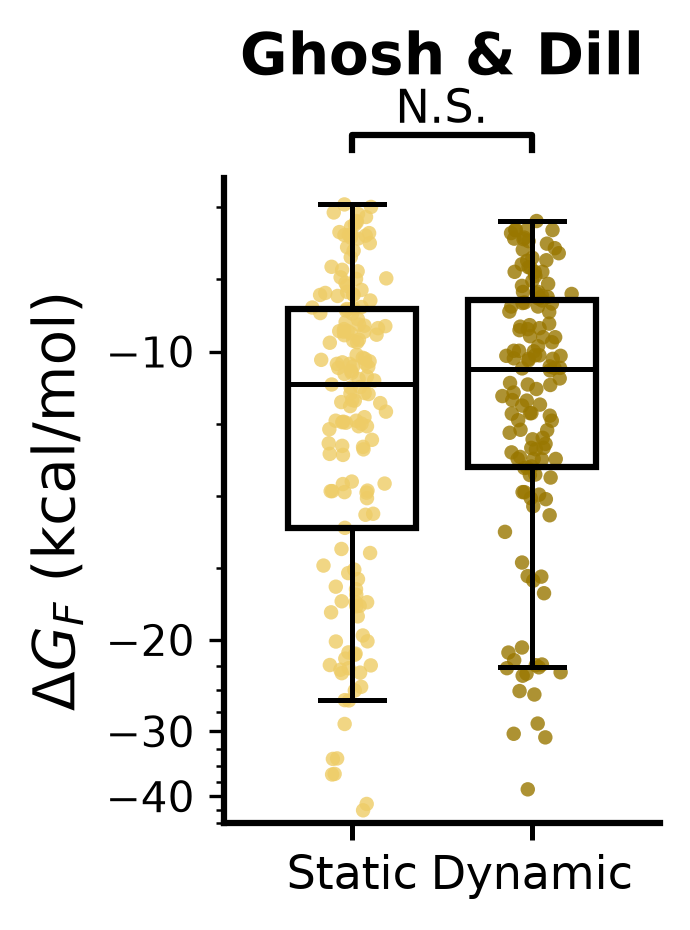

Saved: Supp4B-E.2.svg


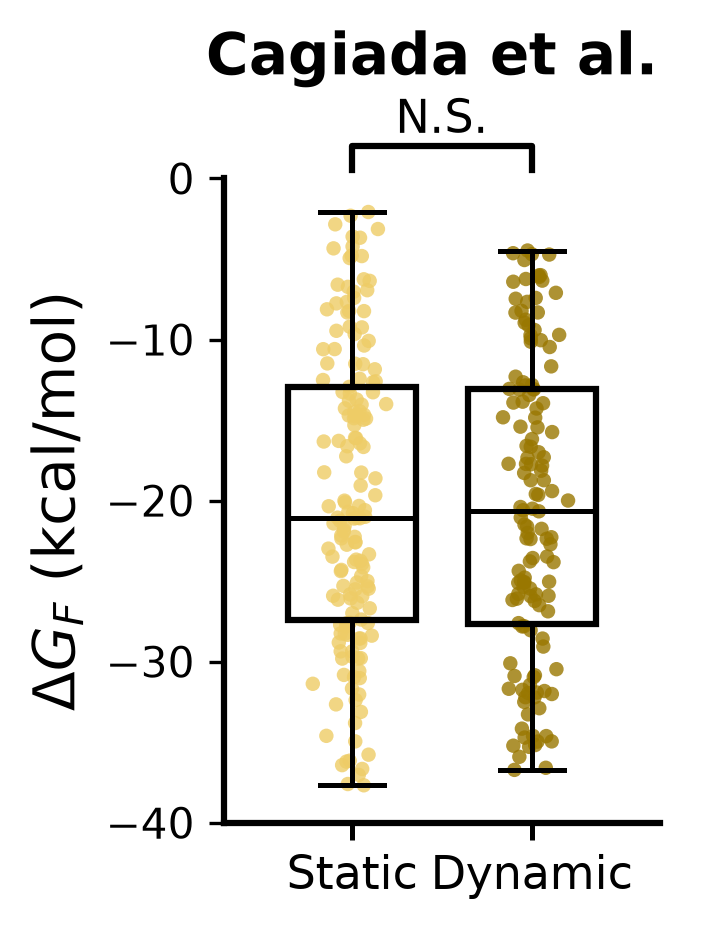

Saved: Supp4B-E.3.svg


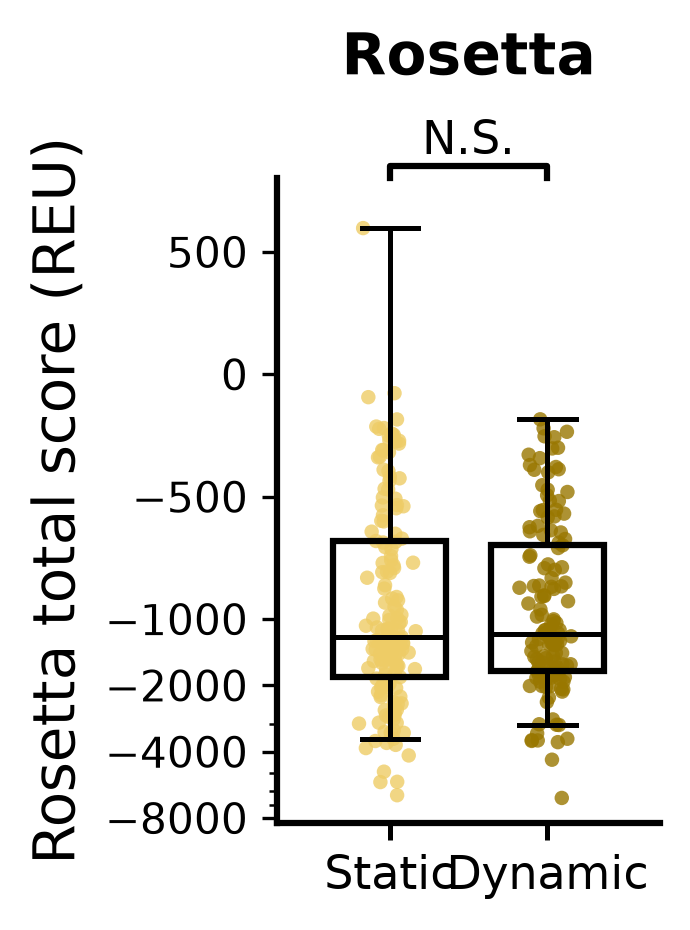

Saved: Supp4B-E.4.svg


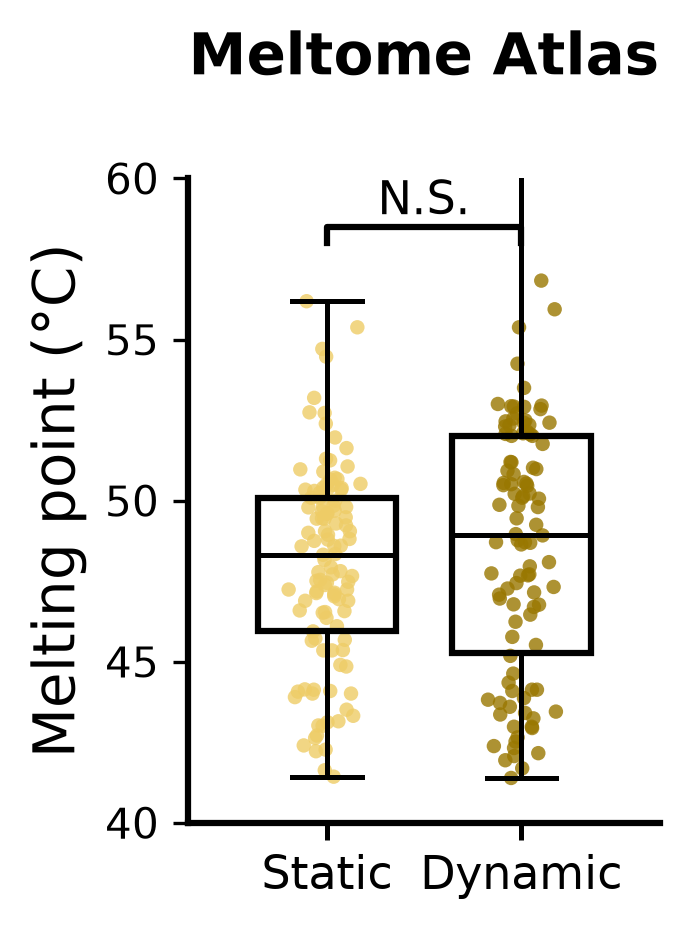

In [9]:
def draw_significance(ax, x1, x2, y, h, text):
    """
    Draws a straight bracket + text at EXACT y position and height h.
    - x1, x2 = x-coordinates of the two groups
    - y = vertical position of the bracket
    - h = height of the vertical bracket lines
    - text = significance stars
    """
    ax.plot([x1, x1, x2, x2],
            [y, y + h, y + h, y],
            lw=1.5, color="black", clip_on=False)
    
    ax.text((x1 + x2) / 2, y + h*1.1, text,
            ha="center", va="bottom",
            fontsize=11)


def base_box_scatter(ax, static_vals, dynamic_vals):
    positions = [1.0, 1.7]

    # === 1. Scatter ===
    for pos, vals, color in zip(
        positions,
        [static_vals, dynamic_vals],
        [MS_COLOR_LIGHT, MS_COLOR_DARK]
    ):
        x_jitter = pos + np.random.normal(0, 0.05, len(vals))
        ax.scatter(x_jitter, vals, s=12, alpha=0.8,
                   color=color, edgecolor="none", zorder=2)

    # === 2. Boxplot ===
    bp = ax.boxplot(
        [static_vals.values, dynamic_vals.values],
        positions=positions,
        widths=0.5,
        patch_artist=True,
        showfliers=False,
        zorder=3
    )

    ax.set_xticks([1, 1.7])
    ax.set_xticklabels(["Top\n10%", "Bottom\n90%"])

    for box in bp["boxes"]:
        box.set_facecolor("none")
        box.set_edgecolor("black")
        box.set_linewidth(1.5)

    for element in ["whiskers", "caps", "medians"]:
        plt.setp(bp[element], color="black", linewidth=1.2)

    # === 3. X-axis labels ===
    ax.set_xticks(positions)
    ax.set_xticklabels(["Static", "Dynamic"],
                       fontsize=11)
    ax.tick_params(axis="x", length=4, width=1.2)

    labs = ax.get_xticklabels()
    labs[0].set_color("black")
    labs[1].set_color("black")

    #  === 4. Spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)

    return positions

figure_counter = 1
for stab_name, static_vals, dynamic_vals in groups_step4:

    if len(static_vals) < 5 or len(dynamic_vals) < 5:
        print("Skipping:", stab_name)
        continue

    fig, ax = plt.subplots(figsize=(2.4, 3.2))

    #  === 5. Base scatter+boxplot
    positions = base_box_scatter(ax, static_vals, dynamic_vals)
    ax.set_ylabel(stab_name, fontsize=11)
    ax.set_title("", fontsize=11)

    #  === 6. Metric-specific axis rules
    if "Rosetta" in stab_name:
        #ax.set_yscale("symlog", linthresh=10)
        ax.set_ylabel("Rosetta total score (REU)", fontsize=14)
        ax.set_title("Rosetta", fontweight='bold')
        ax.set_yscale("symlog", linthresh=1000)
        ax.set_ylim(-8400, 800)
        ax.set_yticks([-8000, -4000, -2000, -1000, -500, 0, 500])
        ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
        #ax.minorticks_on()
        ax.yaxis.set_minor_locator(AutoMinorLocator(4))
        bracket_y = 800   
        bracket_h = 50 

    elif "Meltome" in stab_name or "Tm" in stab_name:
        ax.set_ylabel(r"Melting point (°C)", fontsize=14)
        ax.set_title("Meltome Atlas", fontweight='bold')
        ax.set_ylim(40, 60)
        ax.set_yticks([40, 45, 50, 55, 60])
        bracket_y = 58    
        bracket_h = 0.5

    elif "Cagiada" in stab_name:
        ax.set_ylabel(r"$\Delta G_F$ (kcal/mol)", fontsize=14)
        ax.set_title("Cagiada et al. ", fontweight='bold')
        ax.set_ylim(-40, 0)
        ax.set_yticks([0, -10, -20, -30, -40])
        bracket_y = 0.5
        bracket_h = 1.5
        
    elif "Ghosh-Dill" in stab_name:
        ax.set_ylabel(r"$\Delta G_F$ (kcal/mol)", fontsize=14)
        ax.set_title("Ghosh & Dill", fontweight='bold')
        ax.set_yscale("symlog", linthresh=20)
        ax.set_ylim(-45, -4)
        ax.set_yticks([-10, -20, -30, -40])
        ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
        #ax.minorticks_on()
        ax.yaxis.set_minor_locator(AutoMinorLocator(4))
        bracket_y = -3
        bracket_h = 0.5

    #  === 7. Significance stars
    p_val = [r[2] for r in results if r[0] == stab_name][0]
    stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "N.S."
    draw_significance(ax, positions[0], positions[1], bracket_y, bracket_h, stars)

        # === 9. Save
    plt.tight_layout()
    out = f"Supp4B-E.{figure_counter}.svg"
    plt.savefig(out, dpi=400, bbox_inches="tight")
    print("Saved:", out)

    figure_counter += 1
    plt.show()